[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sampriti-sr/MLP_Course/blob/kshitij-variant/docs/lifecycle/06-baselines.ipynb)

# Baselines

<div class="admonition info">
<p class="admonition-title">What you will be able to do after this page</p>
<ul>
<li>Build a hierarchy of baselines from random calling to a plain model, chosen before seeing the score.</li>
<li>Explain why the ranking rule is part of the model, and why AUC can disagree with decision quality.</li>
<li>Attach a bootstrap interval to a noisy, heavy-tailed metric and read it honestly.</li>
<li>State the bar a future model must clear.</li>
</ul>
</div>

**Prerequisites:** <a href="../05-splitting/">Splitting Strategy</a>. **Dataset:** Online Retail II. **Time:** about 40 minutes.

In [1]:
try:
    import mlp_data
except ImportError:  # e.g. a fresh Colab runtime
    %pip install -q "mlp-course @ git+https://github.com/sampriti-sr/MLP_Course@kshitij-variant"
    import mlp_data

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlp_data import load_retail, retail, style

style.apply()
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 14)
pd.set_option("display.float_format", "{:,.2f}".format)

## The situation

A model's score means nothing on its own. "AUC 0.79" could be excellent or embarrassing, depending on what a trivial rule achieves. A **baseline** is the simplest thing that could possibly work, and it earns its place for four reasons:

1. It sets the **bar** that any real model has to clear, and shows by how much it clears it.
2. It **tests the pipeline**: if a baseline scores nonsense, the bug is in the data or the evaluation, not the model.
3. It is often **good enough**, in which case a complicated model is not worth its cost.
4. It gives you a **plain-language story** for stakeholders: "a simple rule already finds X; the model finds Y".

<div class="admonition note">
<p class="admonition-title">Choose baselines before you look at the validation score</p>
<p>The six baselines below come from what Pages 1 and 4 taught us (value matters; recency and frequency carry signal), not from trying things until the validation number looks good. Heuristics designed <em>after</em> peeking at the answer are tuned to it and make the bar misleadingly easy to clear.</p>
</div>

## Set-up: train on train, judge on validation

Everything learns from the **train** snapshots only, and is judged on the **validation** snapshot. The test snapshot stays untouched.

In [2]:
from mlp_data.metrics import at_risk_report, random_calling_report, bootstrap_interval, K

cleaned = retail.clean_retail(load_retail())
sp = retail.build_splits(cleaned.sales, cleaned.returns, features="full")
train, valid = sp.train, sp.valid
RFM = ["recency_days", "frequency", "monetary"]

def show(table, cols):
    """Format a results table for reading: AUC to 3 places, money with separators, shares as percentages."""
    fmt = {"AUC": "{:.3f}", "avg precision": "{:.3f}", "precision@200": "{:.1%}", "lift@200": "{:.2f}x", "revenue@200": "{:,.0f}",
           "revenue@200 oracle": "{:,.0f}", "revenue@200 % of oracle": "{:.0%}", "brier": "{:.3f}", "log loss": "{:.3f}"}
    return table[cols].apply(lambda col: col.map(fmt[col.name].format))

print(f"train {len(train):,} rows, validation {len(valid):,} rows; call budget K = {K}")
print(f"base rate of buying again: train {train['y'].mean():.1%}, validation {valid['y'].mean():.1%}")

train 16,925 rows, validation 4,324 rows; call budget K = 200
base rate of buying again: train 34.4%, validation 36.6%


## What we measure

We keep the yardstick from Page 1: the account managers phone the **200 customers most at risk of not buying again**. Customers who do not return are called *lapsers*. Each baseline produces a **risk score** per customer; we call the top 200.

| Metric | Question it answers |
|---|---|
| **AUC** | Over *all* customers, how well does the score rank lapsers above returners? (0.5 = chance, 1 = perfect) |
| **Average precision** | Same, but weighted towards getting the top of the list right |
| **precision@200** | Of the 200 we call, what share really would have lapsed? |
| **lift@200** | That precision divided by the lapse rate: how many times better than random? |
| **revenue@200** | Past-year revenue of the lapsers among those 200: the money we may protect |
| **% of oracle** | revenue@200 as a share of the best possible 200 with perfect foresight |
| **Brier, log loss** | How good are the predicted *probabilities* themselves (only for models that output probabilities) |

## Baseline 0: random calling

The floor. Calling 200 customers at random finds lapsers at the lapse rate, and captures their revenue in proportion. We compute it exactly rather than by simulation.

In [3]:
rows = {}
rows["B0 random calling"] = random_calling_report(valid["y"], valid["monetary"], train_rate=train["y"].mean())
show(pd.DataFrame(rows).T, ["AUC", "precision@200", "revenue@200", "revenue@200 oracle", "revenue@200 % of oracle"])

,AUC,precision@200,revenue@200,revenue@200 oracle,revenue@200 % of oracle
B0 random calling,0.500,63.4%,"111,799","999,509",11%


The **oracle** column is the ceiling: if we could see the future and phone exactly the 200 lapsers who spent most, how much would we protect? Random calling captures only a small slice of that.

## Baselines 1 and 2: one-line rules

In [4]:
def evaluate(name, risk=None, p=None, probabilities=False):
    rows[name] = at_risk_report(valid["y"], p, valid["monetary"], risk=risk, probabilities=probabilities)

evaluate("B1 silent longest",   risk=valid["recency_days"])            # the longer since the last order, the riskier
evaluate("B2 fewest orders",    risk=-valid["frequency"])              # the fewer orders in the year, the riskier
print(f"{(valid['frequency'] == 1).sum():,} validation customers are tied at exactly one order; ties are broken at random (fixed seed), so the result does not depend on how the file is sorted")
show(pd.DataFrame(rows).T, ["AUC", "precision@200", "lift@200", "revenue@200", "revenue@200 % of oracle"])

1,559 validation customers are tied at exactly one order; ties are broken at random (fixed seed), so the result does not depend on how the file is sorted


,AUC,precision@200,lift@200,revenue@200,revenue@200 % of oracle
B0 random calling,0.500,63.4%,1.00x,"111,799",11%
B1 silent longest,0.746,89.0%,1.40x,"64,262",6%
B2 fewest orders,0.767,82.5%,1.30x,"51,289",5%


Both rules rank lapsers well (AUC around 0.75), and their top 200 are overwhelmingly real lapsers (precision around 0.8 to 0.9). But look at **revenue@200**: both are *below random calling*. Page 1 found this for recency; it holds out of sample too. The customers who have been quiet longest, or who ordered once, are the small ones. The rules are accurate and nearly worthless in money.

## Baseline 3: a rule that knows value matters

Combine the two ideas: call customers who are both *silent* and *valuable*. We rank each by percentile and multiply. No fitting at all.

In [5]:
pct = lambda s: s.rank(pct=True)
evaluate("B3 silent x valuable", risk=pct(valid["recency_days"]) * pct(valid["monetary"]))
show(pd.DataFrame(rows).T, ["AUC", "precision@200", "revenue@200", "revenue@200 % of oracle"]).tail(1)

,AUC,precision@200,revenue@200,revenue@200 % of oracle
B3 silent x valuable,0.525,76.5%,"483,397",48%


A rule with no model at all now captures a large multiple of random calling's revenue, while its AUC and precision look *worse* than B1 and B2. That is not a contradiction: the rule is aiming at a different target (money), and AUC does not measure money.

## Baseline 4: a plain logistic regression

Now a first real model: logistic regression on recency, frequency and spend. Because spend and frequency are heavy-tailed (Page 4), we log-transform them, then standardise so coefficients are comparable. Wrapping it all in a `Pipeline` means the transformations are learned on the training rows only.

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

logit = make_pipeline(FunctionTransformer(np.log1p), StandardScaler(), LogisticRegression(max_iter=1000))
logit.fit(train[RFM], train["y"])
p_logit = logit.predict_proba(valid[RFM])[:, 1]                       # probability of buying again

evaluate("B4 logistic regression", p=p_logit, probabilities=True)     # risk = 1 - p: call the least likely to return
print("standardised coefficients (log scale):", {c: round(float(w), 2) for c, w in zip(RFM, logit[-1].coef_[0])})
show(pd.DataFrame(rows).T, ["AUC", "avg precision", "precision@200", "revenue@200", "revenue@200 % of oracle", "brier", "log loss"]).loc[["B0 random calling", "B4 logistic regression"]]

standardised coefficients (log scale): {'recency_days': -0.28, 'frequency': 0.78, 'monetary': 0.34}


,AUC,avg precision,precision@200,revenue@200,revenue@200 % of oracle,brier,log loss
B0 random calling,0.500,0.634,63.4%,"111,799",11%,0.233,0.658
B4 logistic regression,0.790,0.844,90.5%,"15,003",2%,0.174,0.524


The model ranks lapsers better than any rule so far (highest AUC and average precision), its probabilities are meaningfully better than a constant (compare its Brier score and log loss, where lower is better, with the constant-rate predictions of random calling in the row above), and its top 200 are mostly real lapsers.

Its **revenue@200**, though, is dismal. Read the coefficients: frequency has by far the largest effect, so the model confidently says "the people who order rarely will lapse". Those are the *smallest* customers. The model is doing exactly what we asked (rank by probability), and probability is not the objective.

<div class="admonition warning">
<p class="admonition-title">Probability of lapsing is not value at risk</p>
<p>Losing a customer worth £50 and losing one worth £50,000 are not the same event, but a probability model treats them identically. If the decision is "who should an account manager phone", the thing to rank by is <em>expected revenue at risk</em>, not probability.</p>
</div>

## Baseline 5: same model, ranked by value at risk

We do not need a new model. Reuse the probabilities from B4 but change *how we rank*: call first the customers with the highest `probability of lapsing × past-year revenue`.

In [7]:
value_at_risk = (1 - p_logit) * valid["monetary"].to_numpy()
evaluate("B5 logistic, ranked by value at risk", risk=value_at_risk, p=p_logit, probabilities=True)
show(pd.DataFrame(rows).T, ["AUC", "precision@200", "revenue@200", "revenue@200 % of oracle"]).tail(2)

,AUC,precision@200,revenue@200,revenue@200 % of oracle
B4 logistic regression,0.790,90.5%,"15,003",2%
"B5 logistic, ranked by value at risk",0.301,40.0%,"614,901",62%


Same probabilities, different decision rule, and revenue@200 leaps. Notice what moved the other way: **AUC and precision@200 fell** (the customers it calls are valuable, so many of them would have returned anyway). An AUC below 0.5 looks alarming, but here it only means this ranking deliberately puts valuable customers first, and valuable customers tend to come back. No single column tells the whole story, which is why we agreed the metric *before* modelling.

## The scoreboard, with honest uncertainty

Revenue is heavy-tailed, so a few big customers can swing a single validation number. We attach a **bootstrap interval** (resample the validation customers with replacement 200 times) to the revenue column, to see which differences are real.

In [8]:
risk_for = {"B1 silent longest": valid["recency_days"].to_numpy(),
            "B2 fewest orders": -valid["frequency"].to_numpy(),
            "B3 silent x valuable": (pct(valid["recency_days"]) * pct(valid["monetary"])).to_numpy(),
            "B4 logistic regression": 1 - p_logit,
            "B5 logistic, ranked by value at risk": value_at_risk}
ci = {name: bootstrap_interval(valid["y"], None, valid["monetary"], metric="revenue@200", risk=r, n_boot=200, seed=0) for name, r in risk_for.items()}

board = pd.DataFrame(rows).T
board["revenue@200 90% interval"] = [("-" if n == "B0 random calling" else f"{ci[n][0]:,.0f} to {ci[n][1]:,.0f}") for n in board.index]
show(board, ["AUC", "precision@200", "revenue@200", "revenue@200 % of oracle"]).assign(**{"revenue@200 90% interval": board["revenue@200 90% interval"]})

,AUC,precision@200,revenue@200,revenue@200 % of oracle,revenue@200 90% interval
B0 random calling,0.500,63.4%,"111,799",11%,-
B1 silent longest,0.746,89.0%,"64,262",6%,"50,388 to 83,680"
B2 fewest orders,0.767,82.5%,"51,289",5%,"48,358 to 74,425"
B3 silent x valuable,0.525,76.5%,"483,397",48%,"360,687 to 652,943"
B4 logistic regression,0.790,90.5%,"15,003",2%,"13,790 to 16,360"
"B5 logistic, ranked by value at risk",0.301,40.0%,"614,901",62%,"434,911 to 819,219"


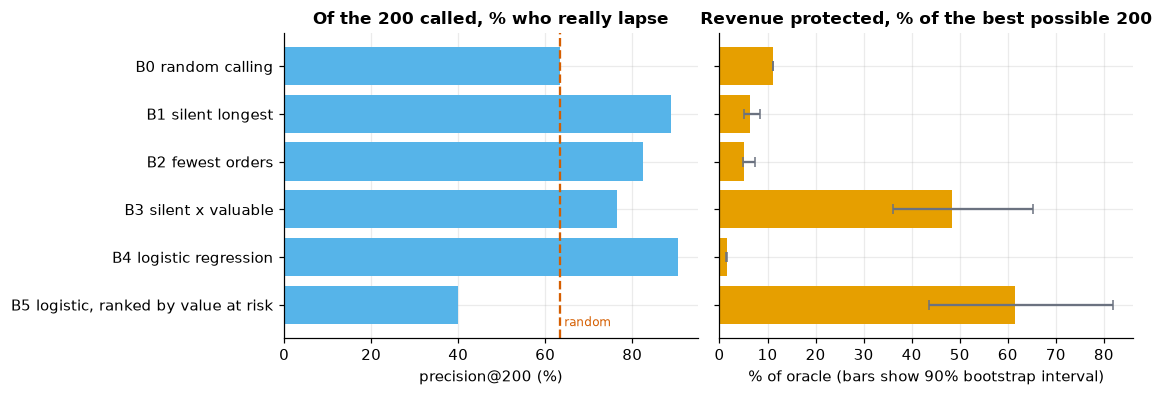

In [9]:
fig, (a, b) = plt.subplots(1, 2, figsize=(10.5, 3.7), sharey=True)
names = list(board.index)[::-1]
a.barh(names, board.loc[names, "precision@200"] * 100, color=style.SKY)
a.axvline((1 - valid["y"]).mean() * 100, color=style.RED, ls="--"); a.text((1 - valid["y"]).mean() * 100 + 1, -0.45, "random", color=style.RED, fontsize=8)
a.set(title="Of the 200 called, % who really lapse", xlabel="precision@200 (%)")
pct_oracle = board.loc[names, "revenue@200 % of oracle"] * 100
err = np.array([[0, 0] if n == "B0 random calling" else [(board.loc[n, "revenue@200"] - ci[n][0]) / board.loc[n, "revenue@200 oracle"] * 100,
                                                          (ci[n][1] - board.loc[n, "revenue@200"]) / board.loc[n, "revenue@200 oracle"] * 100] for n in names]).T
b.barh(names, pct_oracle, xerr=np.clip(err, 0, None), color=style.ORANGE, ecolor=style.GREY, capsize=3)
b.set(title="Revenue protected, % of the best possible 200", xlabel="% of oracle (bars show 90% bootstrap interval)")
plt.tight_layout(); plt.show()

# The claims made in the text, checked rather than asserted:
r = board["revenue@200"]
assert r["B1 silent longest"] < r["B0 random calling"] and r["B2 fewest orders"] < r["B0 random calling"] and r["B4 logistic regression"] < r["B0 random calling"]
assert r["B3 silent x valuable"] > 2 * r["B0 random calling"]
assert board["AUC"]["B4 logistic regression"] > board["AUC"][["B1 silent longest", "B2 fewest orders"]].max()
assert r["B5 logistic, ranked by value at risk"] > r["B3 silent x valuable"]

### Is B5 really better than B3? Compare them *on the same customers*

The two intervals above overlap, which tempts the conclusion "no clear difference". But B3 and B5 are scored on the **same** validation customers, so most of their noise is shared. A **paired bootstrap** resamples customers once and scores both methods on that same sample, which isolates the difference.

In [10]:
from mlp_data.metrics import bootstrap_difference

d = bootstrap_difference(valid["y"], valid["monetary"], risk_for["B5 logistic, ranked by value at risk"], risk_for["B3 silent x valuable"],
                         metric="revenue@200", n_boot=200, seed=0)
print(f"B5 minus B3, revenue@200: mean {d['mean']:+,.0f}, 90% interval {d['low']:+,.0f} to {d['high']:+,.0f}")
print(f"B5 beats B3 in {d['share_a_better']:.0%} of resamples")

B5 minus B3, revenue@200: mean +123,636, 90% interval +17,120 to +249,875
B5 beats B3 in 96% of resamples


**Reading the charts.**

- **Left (accuracy of the call list).** B1, B2 and B4 fill their 200 slots mostly with genuine lapsers, well above the random line. B3 and B5, which chase value, are *less accurate* by this measure.
- **Right (money protected).** The order flips. The three accuracy-optimised methods sit near or below random; the two value-aware ones are many times higher. B5 is highest, and its interval is clear of the three accuracy-first methods.
- **Uncertainty matters, and pairing helps.** The separate intervals of B3 and B5 overlap, yet the paired comparison above shows B5 ahead in nearly every resample, with an interval that stays above zero. So B5 is probably genuinely better than B3, but by a smaller and less certain margin than either is better than the accuracy-first methods. Two methods scored on the same customers should always be compared *paired*.

## What bar must a real model clear?

| Objective | The bar to beat | Source |
|---|---|---|
| Rank lapsers accurately (AUC) | the logistic regression, **B4** | the best plain model |
| Protect revenue within 200 calls | the value-at-risk logistic, **B5** (with the rule **B3** as the no-model alternative) | a model *and* a decision rule |

Any model we build next must beat these **on the same validation snapshot, with the same K**, and should show it beats the *interval*, not only the point estimate.

## Check yourself

<details class="question">
<summary>1. B3 uses no model and no training data, yet protects far more revenue than the logistic regression B4. Does that mean models are useless here?</summary>

No. It means the *decision* matters more than the *model* for this objective. B4 and B5 use the same probabilities; only the ranking rule differs, and that alone moves revenue@200 by a large factor. A better model can still add value on top (it can estimate probabilities more sharply), but only if it is judged and used against the right objective.

</details>

<details class="question">
<summary>2. B5 has a lower AUC than B4. Should we prefer B4?</summary>

Not if the goal is money. AUC measures how well the score separates lapsers from returners across *every* customer; our decision only touches 200 of them and cares about their value. A metric must be chosen from the decision. (We would prefer B4 if the goal were an accurate list of who will lapse, regardless of worth.)

</details>

<details class="question">
<summary>3. Why compute a bootstrap interval for revenue but not worry as much for AUC?</summary>

Revenue is heavy-tailed: a single very large customer can move the total noticeably, so one snapshot of 4,324 customers gives a noisy estimate. AUC averages over every customer and is much steadier. Report an interval wherever one or two rows can swing the number.

</details>

## Exercise

<details class="question">
<summary>The call budget is an assumption. How do B3 and B5's share of the oracle change if the account managers can call only 50, or as many as 500? Predict first.</summary>

```python
for k in (50, 200, 500):
    out = {}
    for name, risk in {"B3": risk_for["B3 silent x valuable"], "B5": value_at_risk}.items():
        r = at_risk_report(valid["y"], None, valid["monetary"], risk=risk, k=k)
        out[name] = f"{r[f'revenue@{k} % of oracle']:.0%} of oracle"
    print(k, out)
```

On this validation snapshot the value-at-risk ranking (B5) keeps roughly 60% of the oracle at every budget, while the percentile-product rule (B3) captures only about a quarter of it at 50 calls and catches up as the budget grows. So the gap between them is largest when the budget is tight and the ranking must put the *right giants* first. Because the budget is a business assumption, report results across a range of K rather than one number.

</details>

## Recap

- A baseline sets the bar, tests the pipeline, may be good enough, and tells the story. Choose baselines **before** looking at the validation score.
- Compare against random first, using exact expectations, then rules, then a plain model.
- **The ranking rule is part of the model.** The same probabilities protect almost nothing ranked by probability and a great deal ranked by value at risk.
- AUC and decision quality can disagree. Choose the metric from the decision and report several.
- With heavy-tailed revenue, attach an interval and do not over-read small gaps.

**Next:** *Feature engineering*, where we try to beat these baselines by giving the model better inputs.